Cog Sci 131 Assignment #1: Neural Networks
Benjamin Baker: Section 1, 3041906884
Tiago Dias: Section 2, 3041128860

***NOTE: Tiago and Ben are in different sections***

Q: 1.1 Instructions.
Assignment #1 CogSci 131 Fall 2026
1
Neural Nets
Group Assignment (Teams of 2 persons)
Only one person submits with the names of the people in the group
Total number of points 200.
Instructions
This assignment will count for two coding assignment. Please submit a working jupyter
notebook with the solution to the questions below. Do not use someone else’s work; all
code has to be your own. Use the .ipynb scripts provided in the modules section. You can
submit a pdf file in addition to your ipynb file, or use the markdown language in the script.
The deadline for this assignment is Wed. October 14th at 11:59 pm (modified). You grade will be
low if you do not submit a working ipynb file! So... watch out!

This first cell contains the given code to initialize the neural network class.

In [41]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


class Neural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.sigmoid(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def costFunctionPrimeRelu(self, X, y):
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.reluPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def forwardRelu(self,X):
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.relu(self.z3)
        return yHat

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J

    def costFunctionRelu(self, X,y):
        self.yHat=self.forwardRelu(X)
        J=0.5*sum((y-self.yHat)**2)
        return J

    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.sigmoidPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2


Target X and y created then normalized to fit between 0 and 1.

In [43]:
X=np.array(([3,5],[5,1],[10,1]),dtype=float)
y=np.array(([75],[80],[93]),dtype=float)
X=X/np.amax(X,axis=0)
y=y/100

Q: 1.2 First Problem. Understand the structure of a neural network.50
Points
Using the example found in neural nets demystified and in the script provided, write a program that minimizes the cost function to a given accuracy set in advance by you. Please
do not get stuck in the meaning of accuracy. This simply means a given threshold that
is reasonable and you think your program could reach, for example 0.1% of the target.

Here, we define a function that is meant to minimize the cost through gradient descent given an alpha (step size/learning rate). The function stops running once the cost is less than the given accuracy. It appends every result to an array so that we can visualize the descent graphically.

In [22]:
def minimize(alpha, accuracyPoop, NN):
    W1_init = NN.W1
    W2_init = NN.W2
    print(W1_init,W2_init)
    cost = NN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = NN.costFunctionPrime(X, y)

        NN.W1 = NN.W1-alpha*dJdW1
        NN.W2 = NN.W2-alpha*dJdW2

        cost = NN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr




Q: Plot the cost vs iteration and see if you get a similar figure to the one I am showing above.Do
this only once! Scalar is a parameter that allows to change the step of the iteration. Some
2
people call this the learning rate for some mysterious reason. Explore what happens if the
learning rate is unusually large. I provide an example in the code.

Here, we display the use of a "moderate" learning rate/scalar and plot it.

[[0.50393868 0.80154092 0.28928347]
 [0.71568238 0.58659379 0.85350513]] [[0.86364971]
 [0.295358  ]
 [0.51592894]]


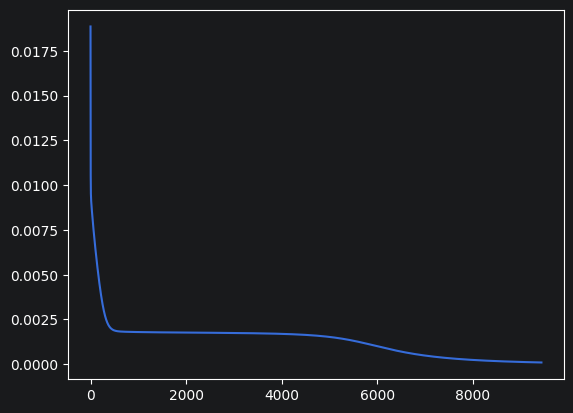

In [23]:
NN=Neural_Network()
cost_arr = (minimize(2, .0001, NN))
plt.plot(cost_arr)

This time down below, we use a large learning rate. The first time we tried this, we observed that the cost jumped up a bit after 900 iterations. This could mean that the function jumped over a valid minimum and had to move back in the other direction, or maybe it started looking for a new min because it missed the first one entirely. This is definitely a downside to a high learning rate.

[[0.91727495 0.938931   0.04237605]
 [0.67631526 0.29507474 0.29295622]] [[0.5740971 ]
 [0.70021679]
 [0.95909123]]


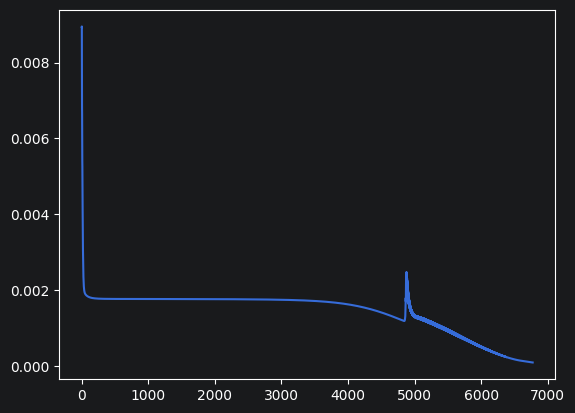

In [46]:
NN_Big=Neural_Network()
cost_arr_Big = (minimize(25, .0001, NN_Big))
plt.plot(cost_arr_Big)

Q: After the minimization
of the cost, do a forward pass and check if the output is close to the real data, and how
close it is. At this point, you should only be going downhill in the cost.

This subtracts the" real" data from the output to see how close it is.

In [49]:
sigmoid_accuracy = NN.forward(X)-y
sigmoid_accuracy

array([[-0.00073069],
       [ 0.00757733],
       [-0.01191826]])

Q: 1.3 Second Problem. Use ReLu instead of sigmoid activation. 100
Points
Use the ReLu activation function instead of the sigmoid function to construct a neural net
of the same dimensions used in 1.2.

Here, we set up the ReLu class. We used a very similar framework to how you/Dr. Ramirez set with the sigmoid function class. One notable modification is that the last layer of our ReLu network must use the sigmoid function to squish all values between 0 and 1.

In [26]:

class ReluNeural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)


Again, we create another function with a similar role to the sigmoid minimize loss function, but with ReLu.

In [27]:
ReluNN = ReluNeural_Network()

def minimizeRelu(alpha, accuracyPoop, ReluNN):
    W1_init = ReluNN.W1
    W2_init = ReluNN.W2
    print(W1_init,W2_init)
    cost = ReluNN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = ReluNN.costFunctionPrime(X, y)

        ReluNN.W1 = ReluNN.W1-alpha*dJdW1
        ReluNN.W2 = ReluNN.W2-alpha*dJdW2

        cost = ReluNN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arrRelu = (minimizeRelu(.05, .0001, ReluNN))

# print(cost_arr)


[[0.80111661 0.09809642 0.92124348]
 [0.06795548 0.65189145 0.67194406]] [[0.18570853]
 [0.20627379]
 [0.49064784]]


Q: Compare how fast this neural network works with the
    one that uses the sigmoid function activation. Do a forward pass and compare with the
    real datea again. Create a plot with the results of the minimization.

Here are our comparisons. First, you can see the total # of iterations for the ReLu, and then the total number of iterations for the sigmoid. For our first trial, it was 2059 (relu) vs. 9436 (sigmoid). Just from a glance, this is a very significant difference. Then, below that is the plot. Lastly, there's an accuracy check using the same method we used for the sigmoid function.

In [28]:
len(cost_arrRelu), len(cost_arr)

(2059, 9436)

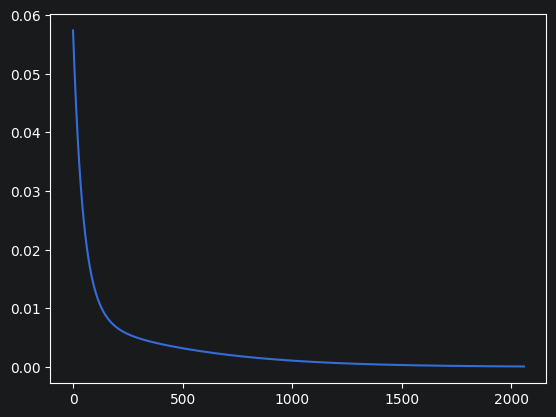

In [29]:
plt.plot(cost_arrRelu)

In [53]:
relu_accuracy = ReluNN.forward(X)-y

print(relu_accuracy)

[[ 0.0078393 ]
 [-0.01152326]
 [-0.00231436]]


Q: Add a new hidden
layer with 3 units and compare with the previous network. Create a graph.

To add an additional hidden layer, we  added a third weight as a class variable, then updated the forward and costfunctionprime functions to account fore this change. We made sure to make the final output a sigmoid while changing the previous output to a relu function to make sure it was all relus until the final output.

In [31]:
class ReluNeural_Network_Extra(object):
    def __init__(self, size):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        self.hiddenLayer_2_Size = size

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.hiddenLayer_2_Size)
        self.W3=np.random.rand(self.hiddenLayer_2_Size,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        self.a3 = self.relu(self.z3)
        self.z4 = np.dot(self.a3, self.W3)
        yHat = self.sigmoid(self.z4)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta4 = np.multiply(-(y-self.yHat), self.sigmoidPrime(self.z4))
        dJdW3=np.dot(self.a3.T, delta4)
        delta3 = np.dot(delta4, self.W3.T)* self.reluPrime(self.z3)
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2, dJdW3

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)



Once the ReLu NN is created with a second hidden layer of 3, we just plugged in an additional djdW3 on top of the existing code to account for the second hidden layer, and it looks more efficient than the previous Relu wih only one hidden layer.

[[0.35039459 0.51378175 0.42125572]
 [0.03367321 0.56860326 0.9542579 ]] [[0.41899643 0.57388097 0.38738825]
 [0.30707348 0.4521589  0.25889644]
 [0.78091868 0.06903517 0.35146292]]


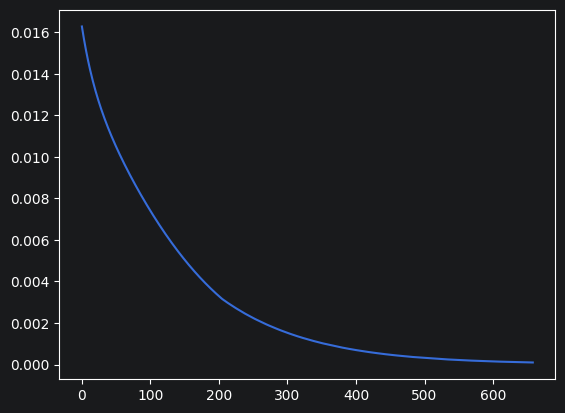

In [32]:
ReluNN_Extra_3 = ReluNeural_Network_Extra(3)

def minimizeRelu_Extra(alpha, accuracyPoop):
    W1_init = ReluNN_Extra_3.W1
    W2_init = ReluNN_Extra_3.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_3.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_3.costFunctionPrime(X, y)

        ReluNN_Extra_3.W1 = ReluNN_Extra_3.W1 - alpha * dJdW1
        ReluNN_Extra_3.W2 = ReluNN_Extra_3.W2 - alpha * dJdW2
        ReluNN_Extra_3.W3 = ReluNN_Extra_3.W3 - alpha * dJdW3

        cost = ReluNN_Extra_3.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra = (minimizeRelu_Extra(.1, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra)


In [33]:
three_accuracy = ReluNN_Extra_3.forward(X) - y

Q: Increase the
number of units in the new hidden layer to 10. Compare again and create a graph again.


Again, we can see the efficiency here. On our first trial, the hidden layer of 3 took more than 600 iterations, while the hidden layer of 10 took less than 300.

[[0.15390971 0.33345542 0.25272854]
 [0.27799936 0.46016139 0.62395506]] [[0.07229942 0.47146435 0.36237695 0.41180363 0.54110158 0.27738851
  0.60074972 0.34984519 0.89959003 0.68002178]
 [0.96492533 0.3437064  0.96803429 0.26794722 0.23059078 0.70868393
  0.27349548 0.01263813 0.29658287 0.25475326]
 [0.22224685 0.26626863 0.91161379 0.21907003 0.69519294 0.51681026
  0.45732186 0.13785653 0.71392231 0.86210666]]


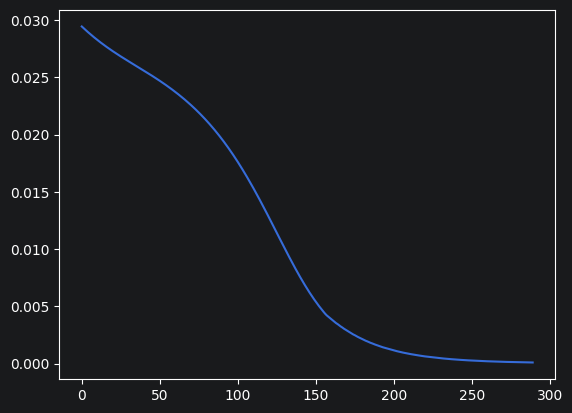

In [34]:
ReluNN_Extra_10 = ReluNeural_Network_Extra(10)

def minimizeRelu_Extra(alpha, accuracyPoop, ReluNN_Extra_10):
    W1_init = ReluNN_Extra_10.W1
    W2_init = ReluNN_Extra_10.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_10.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_10.costFunctionPrime(X, y)

        ReluNN_Extra_10.W1 = ReluNN_Extra_10.W1 - alpha * dJdW1
        ReluNN_Extra_10.W2 = ReluNN_Extra_10.W2 - alpha * dJdW2
        ReluNN_Extra_10.W3 = ReluNN_Extra_10.W3 - alpha * dJdW3

        cost = ReluNN_Extra_10.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra_10= (minimizeRelu_Extra(.1, .0001, ReluNN_Extra_10))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra_10)



In [35]:
ten_accuracy = ReluNN_Extra_10.forward(X) - y

Q: Create a graph with all the neural nets that summarizes the results. Make sure that when
you use RELU, the last step of the forward propagation still uses a sigmoid activation
function (This guarantees that the output of the network is still between 0 and 1, and it
avoids the problem of getting stuck in negative values).

On the left is a graph with all of the results plotted. We can clearly see that the sigmoid function takes the most iterations and the ReLu size 10 takes the least. Then, on the right, we set the x and y scales to logarithmic in order to better see the space.

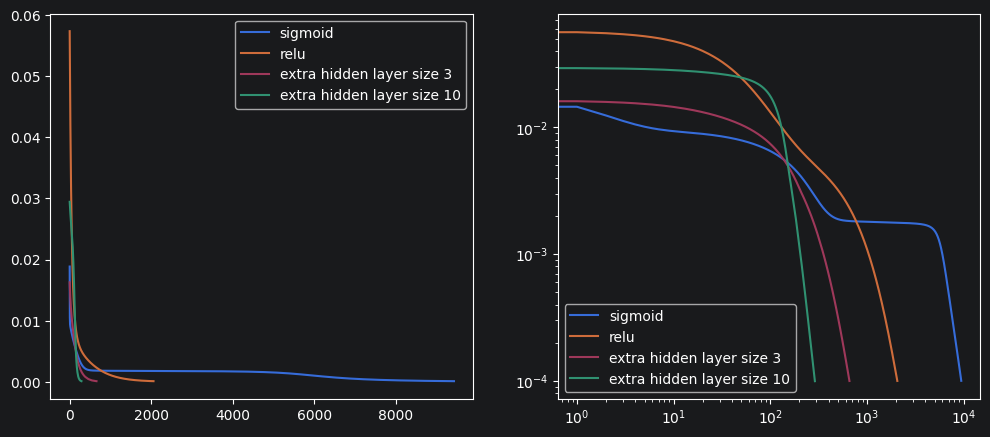

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for ax in (ax1, ax2):
    ax.plot(cost_arr, label = "sigmoid")
    ax.plot(cost_arrRelu, label = "relu")
    ax.plot(cost_arrRelu_Extra, label = "extra hidden layer size 3")
    ax.plot(cost_arrRelu_Extra_10, label = "extra hidden layer size 10")
    ax.legend()

ax2.set_yscale('log')
ax2.set_xscale('log')

plt.show()

In [55]:
# plt.plot(sigmoid_accuracy)
# plt.plot(relu_accuracy)
# plt.plot(three_accuracy)
# plt.plot(ten_accuracy)
# plt.show()

Q: 1.4 Third Problem. Exploration of the W space. 50 Points
Explore the topology of the W spaces by doing a linear interpolation between two of the
solutions. Use the paper titled Essentially no barriers. in the module to get an idea of
how to do this.

To do a linear interpolation between two solutions, we created two separate Neural networks with random weights and minimized them with the same scalar and accuracy. The goal was to have them find their own optimal weights/"valleys" so that we could explore the space between them. To do this, we set up a linspace (a range with set intervals) and had them "walk" from one point to the other and see what the costs were at each point between the two solutions. What we found was that there was often a hill of higher costs between the two more optimized solutions, meaning that they couln't get to the same solution because they started at different points and there was a high cost area between them. Zooming out and looking at the W space with the ends included, it's clear that the whole area is low relative to the rest of the space, meaning that both options are still accurate and even the hill between is relatively small all things considered. The "saddle point" can be seen towards the middle.

[[0.35834358 0.17858564 0.50691341]
 [0.21796292 0.10548804 0.31227948]] [[0.37860264]
 [0.88878361]
 [0.17294463]]
[[0.17301151 0.03190888 0.5116031 ]
 [0.4615881  0.3426791  0.37267386]] [[0.0025051 ]
 [0.50444116]
 [0.22500418]]


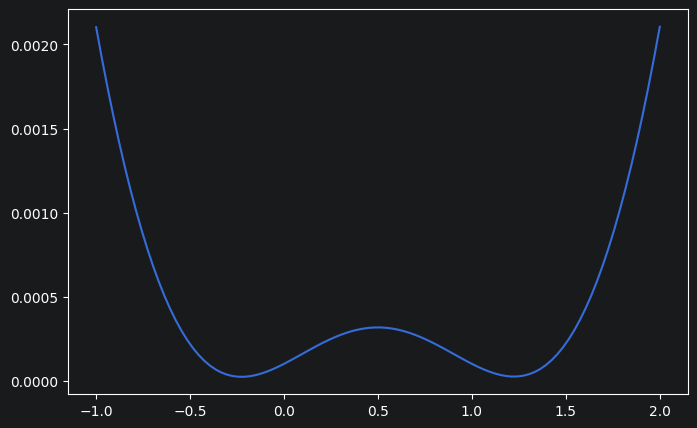

In [57]:
Sys_1 = ReluNeural_Network()
Sys_2 = ReluNeural_Network()

Sol_1 = minimizeRelu(.1, .0001, Sys_1)
Sol_2 = minimizeRelu(.1, .0001,Sys_2)
Sys_1_W1_mirror = Sys_1.W1
Sys_1_W2_mirror = Sys_1.W2
Sys_2_W1_mirror = Sys_2.W1
Sys_2_W2_mirror = Sys_2.W2
def interpolate():
    changes = np.linspace(-1, 2, 100)
    costs = []
    tester = ReluNeural_Network()
    for change in changes:
        tester.W1 = (1.0 - change) * Sys_1_W1_mirror + change * Sys_2_W1_mirror
        tester.W2 = (1.0 - change) * Sys_1_W2_mirror + change * Sys_2_W2_mirror
        costs.append(tester.costFunction(X,y))
    return changes, costs
changes, costs = interpolate()
plt.figure(figsize=(8,5))
plt.plot(changes, costs)

Think of other ways to explore this W space. Explain your thinking in
detail.

An alternate method that we can employ to explore this W space would be the Nudged Elastic Band method (this is the method talked about in the reading). The method above evaluates the cost of the space linearly between the two points. Instead, the NEB method would use perpendicular loss gradients to pull the pivots into lower cost regions. This method would hopefully reveal an even lower path than the one displayed above. The reading refers to this as a "Minimum Energy Path." This would also reveal the saddle point.

More specific to the code, during each iteration, evaluate costFunctionPrime for each pivot point, then subtract the projection along a tangent to the path, and then step along that gradient until a lower loss point.